# Taller 3 Técnicas de Aprendizaje de Máquina

In [2]:
%pip install scikit-learn
%pip install kagglehub
%pip install pandas 
%pip install numpy 
%pip install matplotlib 
%pip install seaborn 
%pip install plotly
# Estas toca instalarlas tambien en el terminal de la computadora, no solo en el notebook.

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


...


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import sklearn 

c:\Users\diego\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
# Download latest version
path = kagglehub.dataset_download("vjchoudhary7/customer-segmentation-tutorial-in-python")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\diego\.cache\kagglehub\datasets\vjchoudhary7\customer-segmentation-tutorial-in-python\versions\1


In [5]:
df = pd.read_csv(path + "/Mall_Customers.csv")
df.head()


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## Comprensión del Dataset

### Columnas y tipos de datos

In [6]:
print(df.dtypes)

CustomerID                 int64
Gender                    object
Age                        int64
Annual Income (k$)         int64
Spending Score (1-100)     int64
dtype: object


### Análisis gráfico

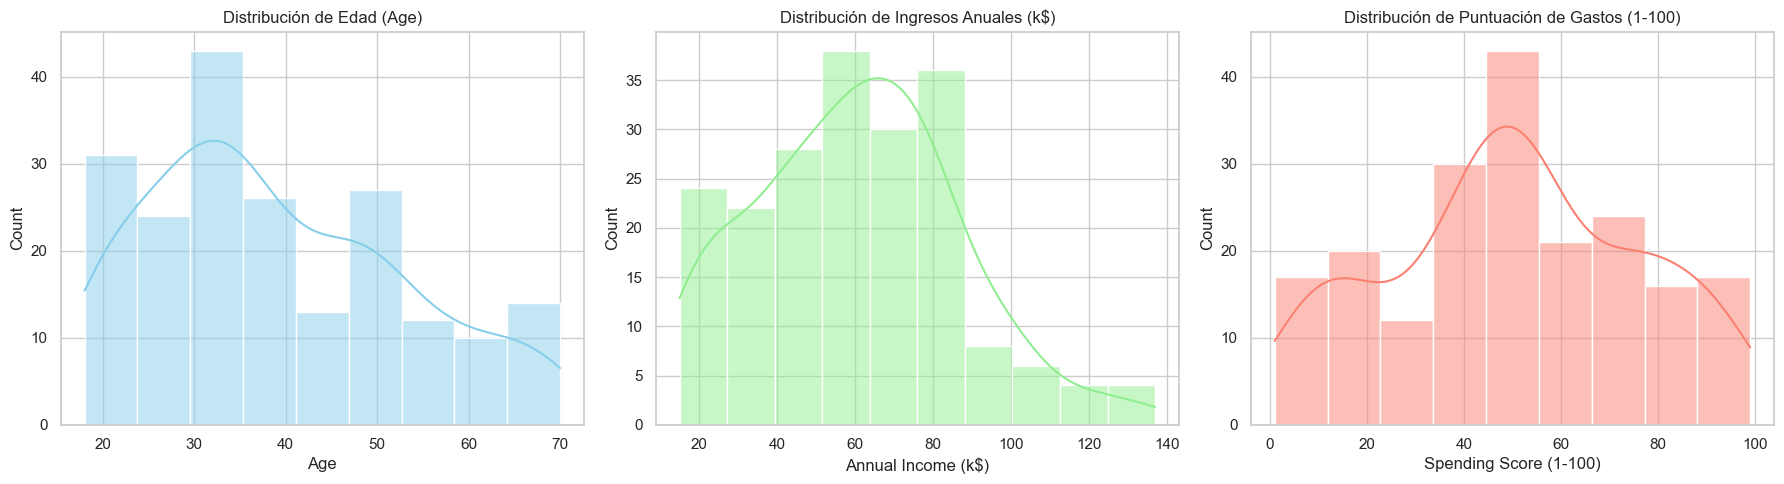

In [7]:
# Visualización de la distribución de las variables numéricas
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df['Age'], kde=True, color='skyblue', ax=axes[0])
axes[0].set_title('Distribución de Edad (Age)')

sns.histplot(df['Annual Income (k$)'], kde=True, color='lightgreen', ax=axes[1])
axes[1].set_title('Distribución de Ingresos Anuales (k$)')

sns.histplot(df['Spending Score (1-100)'], kde=True, color='salmon', ax=axes[2])
axes[2].set_title('Distribución de Puntuación de Gastos (1-100)')

plt.tight_layout()
plt.show()

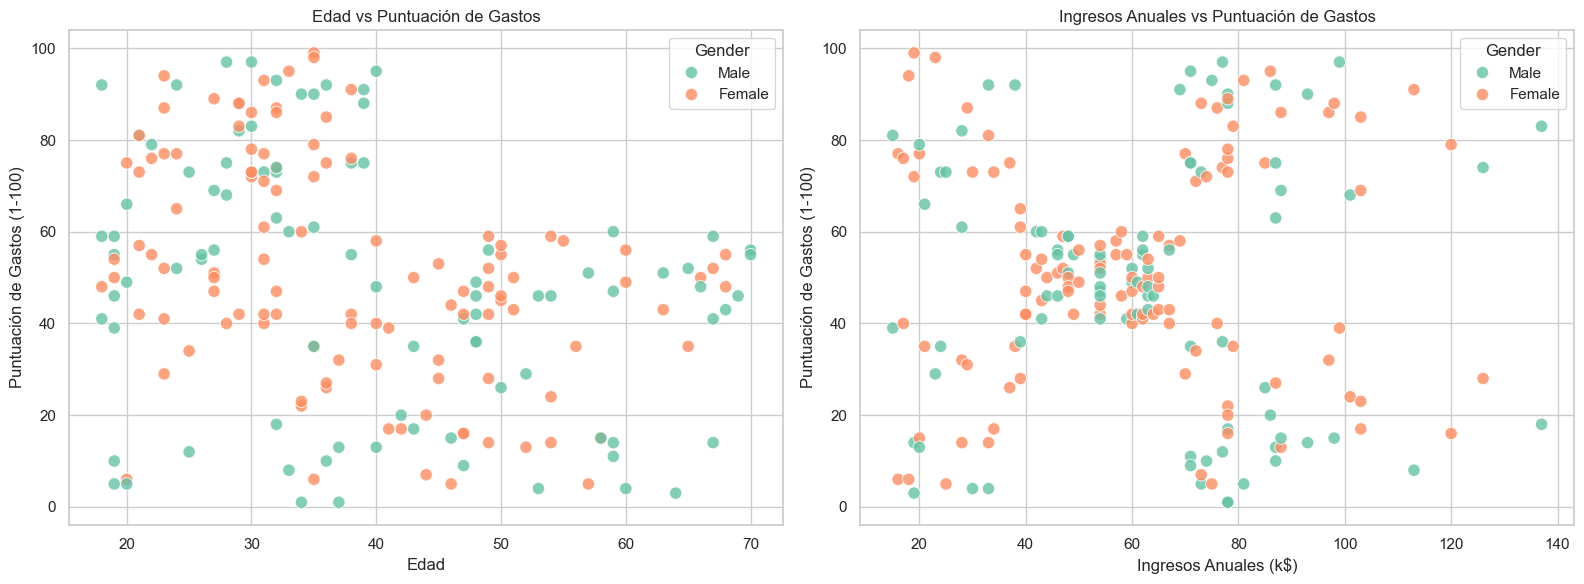

In [8]:
# Gráficos de dispersión para visualizar la relación entre las variables numéricas

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Age vs Spending Score
sns.scatterplot(data=df, x='Age', y='Spending Score (1-100)', 
                hue='Gender', palette='Set2', s=80, alpha=0.8, ax=axes[0])
axes[0].set_title('Edad vs Puntuación de Gastos')
axes[0].set_xlabel('Edad')
axes[0].set_ylabel('Puntuación de Gastos (1-100)')

# Annual Income vs Spending Score
sns.scatterplot(data=df, x='Annual Income (k$)', y='Spending Score (1-100)', 
                hue='Gender', palette='Set2', s=80, alpha=0.8, ax=axes[1])
axes[1].set_title('Ingresos Anuales vs Puntuación de Gastos')
axes[1].set_xlabel('Ingresos Anuales (k$)')
axes[1].set_ylabel('Puntuación de Gastos (1-100)')

plt.tight_layout()
plt.show()

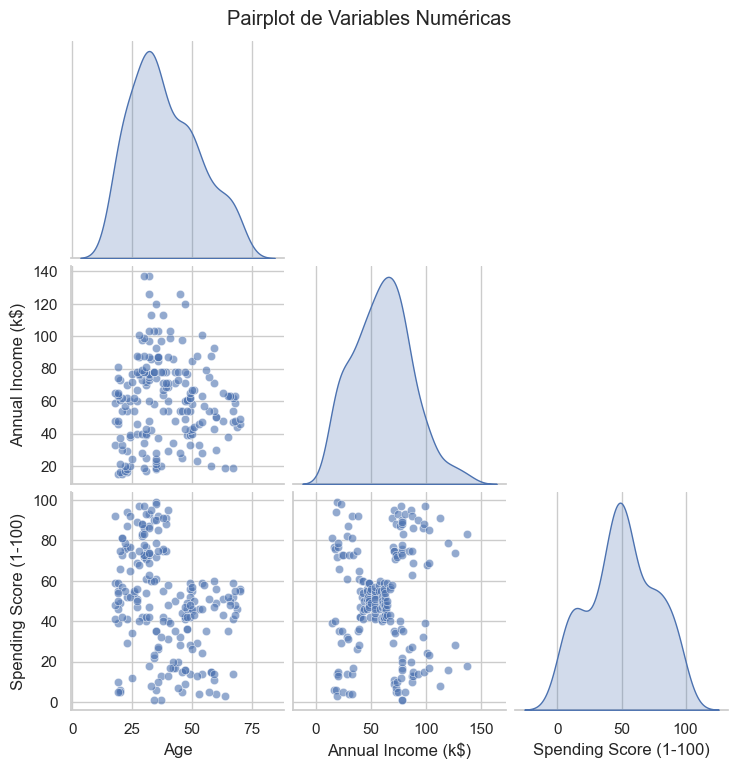

In [9]:
# Gráfico de dispersión general

vars_numericas = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
sns.pairplot(df[vars_numericas], diag_kind='kde', corner=True, plot_kws={'alpha': 0.6})
plt.suptitle('Pairplot de Variables Numéricas', y=1.02)
plt.show()

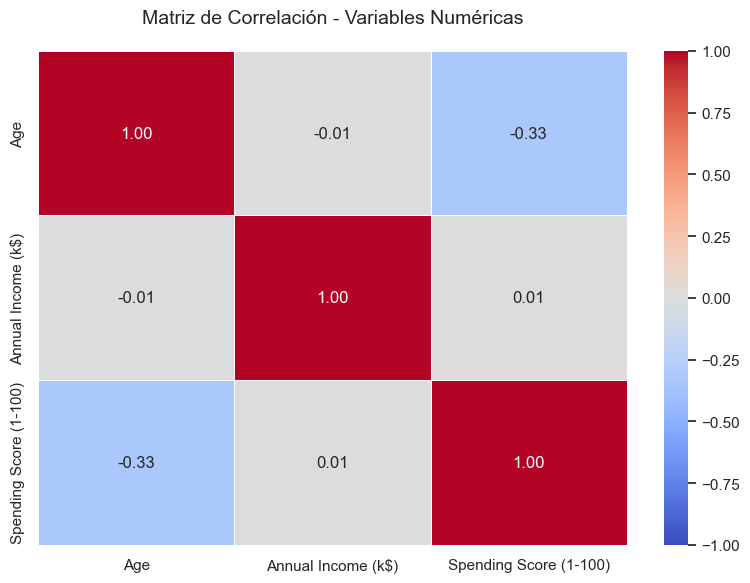

In [10]:
vars_numericas = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
datos_num = df[vars_numericas]

# 2. Calculamos la matriz de correlación (coeficiente de Pearson)
matriz_corr = datos_num.corr()

# 3. Configuramos y renderizamos el mapa de calor
plt.figure(figsize=(8, 6))

sns.heatmap(matriz_corr, 
            annot=True,              # Muestra los coeficientes numéricos exactos
            cmap='coolwarm',         # Rojo para positiva, azul para negativa
            fmt=".2f",               # Redondeo a 2 decimales
            linewidths=0.5,          # Separación entre celdas
            vmin=-1, vmax=1)         # Límites de la escala de Pearson

plt.title('Matriz de Correlación - Variables Numéricas', pad=20, fontsize=14)
plt.tight_layout()
plt.show()

## Limpieza de Datos

In [11]:
df = df.drop(columns=['CustomerID'])  # Eliminamos la columna CustomerID ya que no es relevante para el clustering

df = df.drop(columns=['Gender'])  # Eliminamos la columna Gender ya que es categórica y no se utilizará en el clustering

In [ ]:
# Escalado de datos: Método escogido: StandardScaler
from sklearn.preprocessing import StandardScaler
vars_numericas = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
datos_para_modelo = df[vars_numericas]

# 2. Instanciar el escalador
scaler = StandardScaler()

# 3. Ajustar y transformar los datos
# fit_transform calcula la media y desviación estándar, y luego aplica la fórmula.
# El resultado 'X' es directamente la matriz numpy consolidada que necesitas.
X = scaler.fit_transform(datos_para_modelo)

# Opcional: Visualizar los primeros registros escalados
df_scaled = pd.DataFrame(X, columns=vars_numericas) q   
print("Vista de los datos escalados (media ~ 0, varianza = 1):")
print(df_scaled.head())

Vista de los datos escalados (media ~ 0, varianza = 1):
        Age  Annual Income (k$)  Spending Score (1-100)
0 -1.424569           -1.738999               -0.434801
1 -1.281035           -1.738999                1.195704
2 -1.352802           -1.700830               -1.715913
3 -1.137502           -1.700830                1.040418
4 -0.563369           -1.662660               -0.395980


## Verificacion de resultados y selección de K

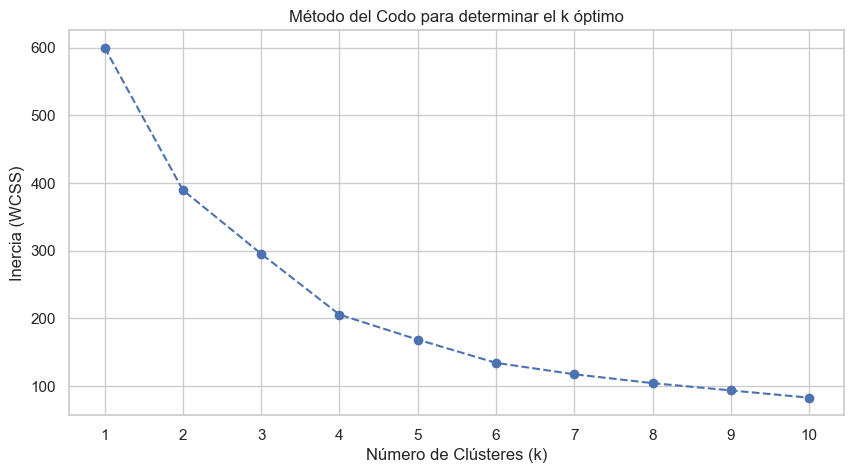

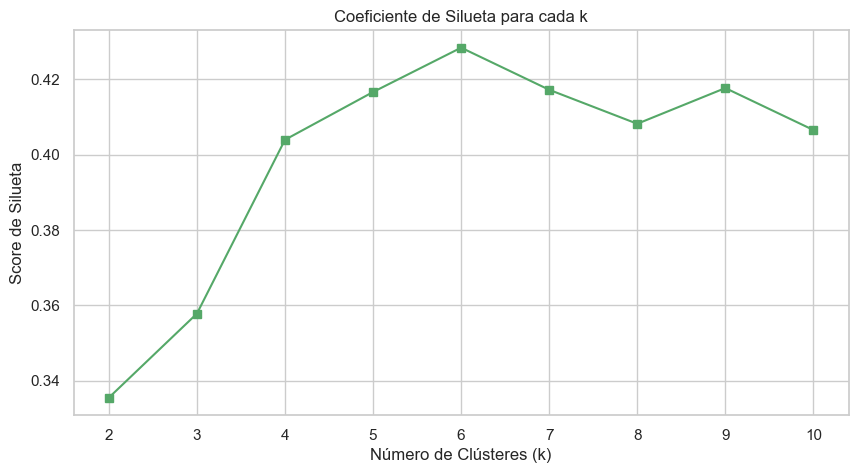

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

X_scaled = df_scaled
# Listas para guardar las métricas de cada iteración
inercia = []
valores_silueta = []

# El taller pide ejecutar el modelo variando k entre 1 y 10
rango_k = range(1, 11)

for k in rango_k:
    # Inicializamos el modelo con k-means++ para evitar malas convergencias
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    
    # 1. Almacenar la Inercia (Suma de errores cuadráticos intra-clúster - WCSS)
    inercia.append(kmeans.inertia_)
    
    # 2. Calcular el Coeficiente de Silueta 
    # (Ojo: la silueta requiere al menos 2 clústeres para poder comparar distancias)
    if k > 1:
        score = silhouette_score(X_scaled, kmeans.labels_)
        valores_silueta.append(score)

# --- Gráfica 1: Método del Codo (Elbow Method) ---
plt.figure(figsize=(10, 5))
plt.plot(rango_k, inercia, marker='o', linestyle='--', color='b')
plt.title('Método del Codo para determinar el k óptimo')
plt.xlabel('Número de Clústeres (k)')
plt.ylabel('Inercia (WCSS)')
plt.xticks(rango_k)
plt.grid(True)
plt.show()

# --- Gráfica 2: Coeficiente de Silueta (Silhouette Score) ---
# Empezamos el rango en 2 porque no hay silueta para k=1
plt.figure(figsize=(10, 5))
plt.plot(range(2, 11), valores_silueta, marker='s', linestyle='-', color='g')
plt.title('Coeficiente de Silueta para cada k')
plt.xlabel('Número de Clústeres (k)')
plt.ylabel('Score de Silueta')
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

## Depuración y análisis del negocio

In [15]:
import pandas as pd
from sklearn.cluster import KMeans

# 1. Entrenar el modelo definitivo con k=5
kmeans_final = KMeans(n_clusters=5, init='k-means++', random_state=42, n_init=10)
kmeans_final.fit(X_scaled)

# 2. Extraer los centroides finales (aún están en la escala transformada)
centroides_escalados = kmeans_final.cluster_centers_

# 3. Revertir el escalado para interpretarlos en su escala original
centroides_originales = scaler.inverse_transform(centroides_escalados)

# 4. Crear un DataFrame para visualizar y perfilar los grupos
# Ajusta los nombres de las columnas si usaste menos variables
columnas = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
df_centroides = pd.DataFrame(centroides_originales, columns=columnas)
df_centroides.index = [f'Cluster {i}' for i in range(5)]

print("Centroides en escala original:")
display(df_centroides)

Centroides en escala original:


,Age,Annual Income (k$),Spending Score (1-100)
Cluster 0,46.250000,26.750000,18.350000
Cluster 1,25.185185,41.092593,62.240741
Cluster 2,32.875000,86.100000,81.525000
Cluster 3,39.871795,86.102564,19.358974
Cluster 4,55.638298,54.382979,48.851064


## Comparación de Modelos

In [16]:
import time
from sklearn.cluster import KMeans

# 1. Modelo con inicialización puramente aleatoria
inicio_random = time.time()
kmeans_random = KMeans(n_clusters=5, init='random', n_init=1, random_state=42)
kmeans_random.fit(X_scaled)
tiempo_random = time.time() - inicio_random

# 2. Modelo con inicialización k-means++ (Librería)
inicio_kpp = time.time()
kmeans_kpp = KMeans(n_clusters=5, init='k-means++', n_init=1, random_state=42)
kmeans_kpp.fit(X_scaled)
tiempo_kpp = time.time() - inicio_kpp

print("--- Comparación de Convergencia e Inercia ---")
print(f"Init Aleatoria -> Inercia: {kmeans_random.inertia_:.2f} | Iteraciones: {kmeans_random.n_iter_} | Tiempo: {tiempo_random:.4f}s")
print(f"Init K-Means++ -> Inercia: {kmeans_kpp.inertia_:.2f} | Iteraciones: {kmeans_kpp.n_iter_} | Tiempo: {tiempo_kpp:.4f}s")

--- Comparación de Convergencia e Inercia ---
Init Aleatoria -> Inercia: 190.48 | Iteraciones: 6 | Tiempo: 0.0038s
Init K-Means++ -> Inercia: 169.89 | Iteraciones: 7 | Tiempo: 0.0044s
